# Robust American Sign Language Alphabet Recognition

DATAX504 Final Project

Student: Sayumini Dissanayake
Student ID: 1722506

Problem type: Image Classification
Framework: Keras / TensorFlow

**Kaggle version.** Attach datasets `grassknoted/asl-alphabet` and `danrasband/asl-alphabet-test`, set Accelerator = GPU, Internet = On.


## 1. Setup

In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Keras is ready!")

# Reproducibility: fix Python, NumPy and TensorFlow seeds
keras.utils.set_random_seed(42)


Keras is ready!


## 2. Locate data (Kaggle: attach both datasets with 'Add Input')

In [4]:
import os
from pathlib import Path

# Find the two attached datasets automatically (folder names differ between Kaggle sessions).
# A folder is a "class root" if it contains sub-folders A, B, Z and space.
candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    if {"A", "B", "Z", "space"}.issubset(set(dirs)):
        n_A = len([f for f in os.listdir(os.path.join(root, "A")) if os.path.isfile(os.path.join(root, "A", f))])
        candidates.append((root, n_A))
        print(f"{root}  ->  {n_A} images in class A")
        dirs[:] = []   # do not descend further

assert len(candidates) >= 2, "Attach BOTH datasets (Add Input) and re-run. Found: %s" % candidates
MAIN_DATA_DIR     = max(candidates, key=lambda x: x[1])[0]   # ~3000 images per class
EXTERNAL_DATA_DIR = min(candidates, key=lambda x: x[1])[0]   # 30 images per class

print("\nMain dataset:    ", MAIN_DATA_DIR)
print("External dataset:", EXTERNAL_DATA_DIR)


/kaggle/input/datasets/danrasband/asl-alphabet-test  ->  30 images in class A
/kaggle/input/datasets/grassknoted/asl-alphabet/asl_alphabet_train/asl_alphabet_train  ->  3000 images in class A

Main dataset:     /kaggle/input/datasets/grassknoted/asl-alphabet/asl_alphabet_train/asl_alphabet_train
External dataset: /kaggle/input/datasets/danrasband/asl-alphabet-test


In [5]:
classes = sorted(os.listdir(EXTERNAL_DATA_DIR))

print("Number of classes:", len(classes))
print()

total_images = 0

for class_name in classes:
    class_path = os.path.join(EXTERNAL_DATA_DIR, class_name)
    count = len([
        f for f in os.listdir(class_path)
        if os.path.isfile(os.path.join(class_path, f))
    ])
    total_images += count
    print(f"{class_name:10s} -> {count} images")

print()
print("Total external images:", total_images)

Number of classes: 30

A          -> 30 images
B          -> 30 images
C          -> 30 images
D          -> 30 images
E          -> 30 images
F          -> 30 images
G          -> 30 images
H          -> 30 images
I          -> 30 images
J          -> 30 images
K          -> 30 images
L          -> 30 images
M          -> 30 images
N          -> 30 images
O          -> 30 images
P          -> 30 images
Q          -> 30 images
R          -> 30 images
S          -> 30 images
T          -> 30 images
U          -> 30 images
V          -> 30 images
W          -> 30 images
X          -> 30 images
Y          -> 30 images
Z          -> 30 images
asl-alphabet-test -> 0 images
del        -> 30 images
nothing    -> 30 images
space      -> 30 images

Total external images: 870


## 3. Stratified 80/10/10 split

In [6]:
from pathlib import Path
from sklearn.model_selection import train_test_split

# Collect all image paths and their class labels
image_paths = []
labels = []

for class_name in sorted(os.listdir(MAIN_DATA_DIR)):
    class_path = Path(MAIN_DATA_DIR) / class_name

    if class_path.is_dir():
        for image_file in class_path.iterdir():
            if image_file.is_file():
                image_paths.append(str(image_file))
                labels.append(class_name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print("Number of classes:", len(set(labels)))

Total images: 87000
Total labels: 87000
Number of classes: 29


In [7]:
# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Second split: divide the temporary 20% equally
# → 10% validation and 10% internal test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Internal test images:", len(X_test))

Training images: 69600
Validation images: 8700
Internal test images: 8700


In [8]:
# Create a fixed class-to-number mapping
class_names = sorted(set(labels))

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Class mapping:")
for index, class_name in index_to_class.items():
    print(f"{index:2d} -> {class_name}")

Class mapping:
 0 -> A
 1 -> B
 2 -> C
 3 -> D
 4 -> E
 5 -> F
 6 -> G
 7 -> H
 8 -> I
 9 -> J
10 -> K
11 -> L
12 -> M
13 -> N
14 -> O
15 -> P
16 -> Q
17 -> R
18 -> S
19 -> T
20 -> U
21 -> V
22 -> W
23 -> X
24 -> Y
25 -> Z
26 -> del
27 -> nothing
28 -> space


In [9]:
y_train_encoded = [class_to_index[label] for label in y_train]
y_val_encoded = [class_to_index[label] for label in y_val]
y_test_encoded = [class_to_index[label] for label in y_test]

print("Example original labels:")
print(y_train[:10])

print("\nExample encoded labels:")
print(y_train_encoded[:10])

Example original labels:
['A', 'Y', 'Z', 'Z', 'H', 'del', 'nothing', 'U', 'E', 'X']

Example encoded labels:
[0, 24, 25, 25, 7, 26, 27, 20, 4, 23]


In [10]:
from collections import Counter

print("Training distribution:")
print(Counter(y_train).most_common())

print("\nValidation distribution:")
print(Counter(y_val).most_common())

print("\nInternal test distribution:")
print(Counter(y_test).most_common())

Training distribution:
[('A', 2400), ('Y', 2400), ('Z', 2400), ('H', 2400), ('del', 2400), ('nothing', 2400), ('U', 2400), ('E', 2400), ('X', 2400), ('I', 2400), ('W', 2400), ('N', 2400), ('B', 2400), ('S', 2400), ('O', 2400), ('F', 2400), ('L', 2400), ('V', 2400), ('Q', 2400), ('P', 2400), ('C', 2400), ('D', 2400), ('J', 2400), ('space', 2400), ('G', 2400), ('K', 2400), ('R', 2400), ('T', 2400), ('M', 2400)]

Validation distribution:
[('A', 300), ('Y', 300), ('Z', 300), ('B', 300), ('G', 300), ('K', 300), ('del', 300), ('L', 300), ('R', 300), ('nothing', 300), ('U', 300), ('space', 300), ('N', 300), ('E', 300), ('V', 300), ('J', 300), ('I', 300), ('D', 300), ('W', 300), ('M', 300), ('F', 300), ('H', 300), ('T', 300), ('P', 300), ('C', 300), ('S', 300), ('O', 300), ('Q', 300), ('X', 300)]

Internal test distribution:
[('G', 300), ('space', 300), ('A', 300), ('V', 300), ('C', 300), ('E', 300), ('S', 300), ('P', 300), ('K', 300), ('X', 300), ('J', 300), ('T', 300), ('R', 300), ('I', 300)

## 4. Input pipelines (128x128)

In [11]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train_encoded)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val_encoded)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_encoded)
)

train_ds = (
    train_ds
    .shuffle(10000, seed=42)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

I0000 00:00:1791324061.267945      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791324061.272931      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow datasets created successfully!


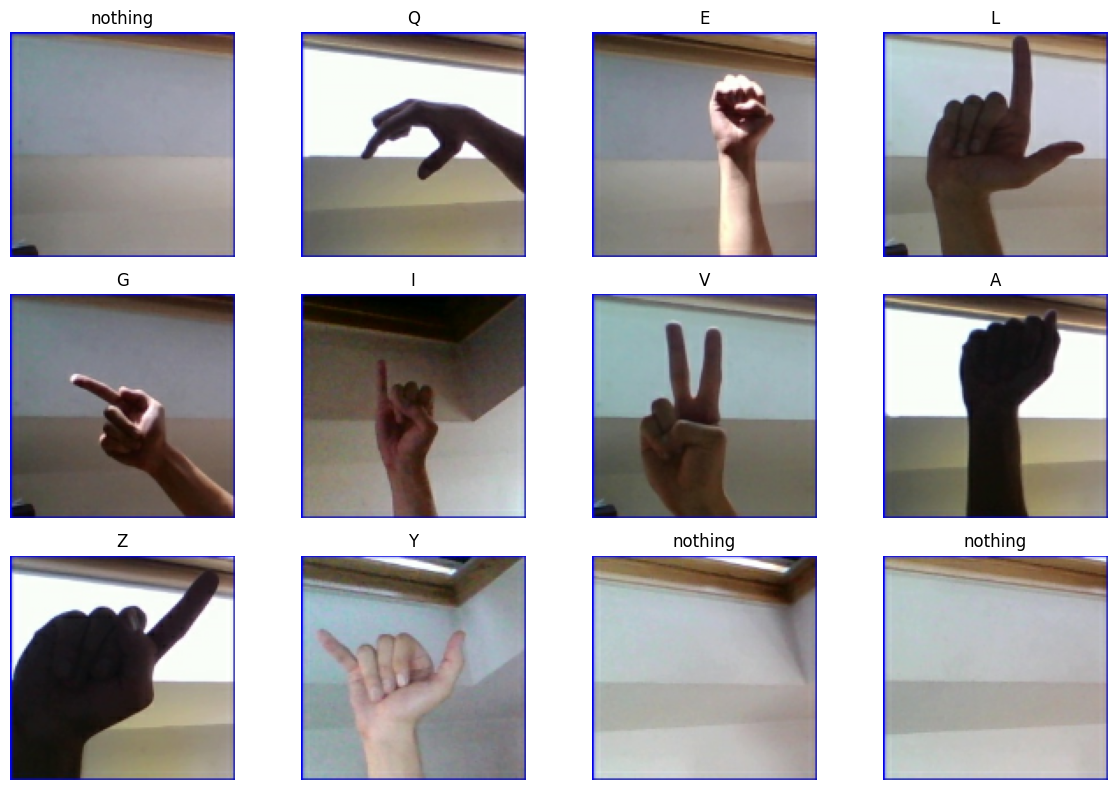

In [12]:
plt.figure(figsize=(12, 8))

for images, batch_labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i])
        plt.title(index_to_class[int(batch_labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
print("PROJECT CONFIGURATION")
print("=" * 40)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", len(class_names))
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Internal test images:", len(X_test))
print("External test images: 870 (locked)")

PROJECT CONFIGURATION
Image size: (128, 128)
Batch size: 32
Number of classes: 29
Training images: 69600
Validation images: 8700
Internal test images: 8700
External test images: 870 (locked)


## 5. M0 - CNN baseline

In [14]:
NUM_CLASSES = len(class_names)

baseline_cnn = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,308,381 (12.62 MB)

 Trainable params: 3,308,381 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
baseline_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("M0 compiled successfully!")

M0 compiled successfully!


In [16]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_baseline_cnn.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Training callbacks ready!")

Training callbacks ready!


In [17]:
history_m0 = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/15


2026-10-06 22:01:09.997579: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 22:01:10.145741: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


   4/2175 ━━━━━━━━━━━━━━━━━━━━ 36s 17ms/step - accuracy: 0.0339 - loss: 3.3857  

I0000 00:00:1791324072.459642     119 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2175/2175 ━━━━━━━━━━━━━━━━━━━━ 430s 195ms/step - accuracy: 0.5930 - loss: 1.2781 - val_accuracy: 0.9451 - val_loss: 0.2113
Epoch 2/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 65s 30ms/step - accuracy: 0.8621 - loss: 0.3837 - val_accuracy: 0.9832 - val_loss: 0.0665
Epoch 3/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9140 - loss: 0.2401 - val_accuracy: 0.9876 - val_loss: 0.0454
Epoch 4/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9392 - loss: 0.1716 - val_accuracy: 0.9941 - val_loss: 0.0212
Epoch 5/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9502 - loss: 0.1430 - val_accuracy: 0.9969 - val_loss: 0.0101
Epoch 6/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9585 - loss: 0.1206 - val_accuracy: 0.9983 - val_loss: 0.0079
Epoch 7/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9646 - loss: 0.1009 - val_accuracy: 0.9977 - val_loss: 0.0070
Epoch 8/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9699 - loss: 0.

In [18]:
# Evaluate M0 on the internal test set

y_true_m0 = np.concatenate([y.numpy() for _, y in test_ds])

y_prob_m0 = baseline_cnn.predict(test_ds)
y_pred_m0 = np.argmax(y_prob_m0, axis=1)

m0_accuracy = accuracy_score(y_true_m0, y_pred_m0)
m0_macro_f1 = f1_score(y_true_m0, y_pred_m0, average="macro")

print(f"M0 Internal Test Accuracy: {m0_accuracy:.4f}")
print(f"M0 Internal Test Macro-F1: {m0_macro_f1:.4f}")

272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step
M0 Internal Test Accuracy: 0.9984
M0 Internal Test Macro-F1: 0.9984


In [19]:
# Detailed classification report for M0

print(classification_report(
    y_true_m0,
    y_pred_m0,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       300
           B     1.0000    1.0000    1.0000       300
           C     1.0000    1.0000    1.0000       300
           D     1.0000    1.0000    1.0000       300
           E     1.0000    0.9967    0.9983       300
           F     1.0000    1.0000    1.0000       300
           G     1.0000    1.0000    1.0000       300
           H     1.0000    1.0000    1.0000       300
           I     1.0000    1.0000    1.0000       300
           J     0.9967    1.0000    0.9983       300
           K     1.0000    1.0000    1.0000       300
           L     1.0000    1.0000    1.0000       300
           M     1.0000    0.9933    0.9967       300
           N     0.9934    1.0000    0.9967       300
           O     1.0000    1.0000    1.0000       300
           P     1.0000    1.0000    1.0000       300
           Q     1.0000    1.0000    1.0000       300
           R     1.0000    

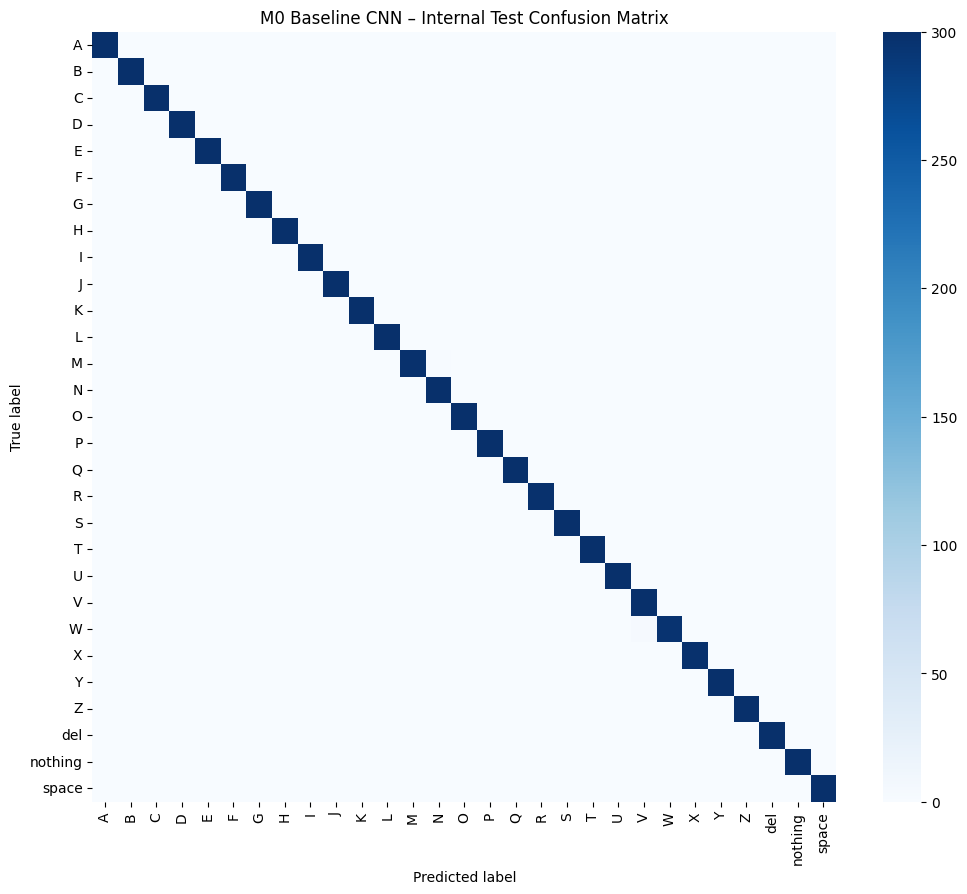

In [20]:
# Confusion matrix for M0

cm_m0 = confusion_matrix(y_true_m0, y_pred_m0)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_m0,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("M0 Baseline CNN – Internal Test Confusion Matrix")
plt.show()

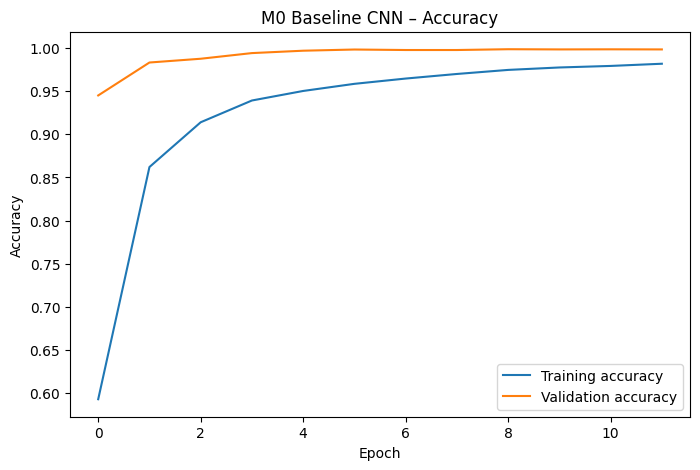

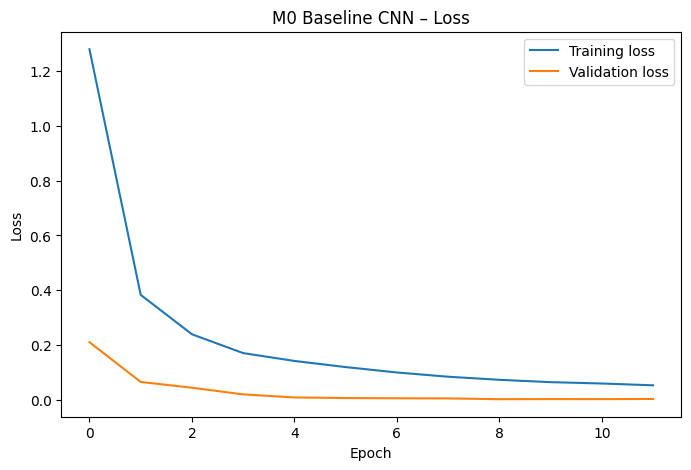

In [21]:
# M0 training curves

plt.figure(figsize=(8, 5))
plt.plot(history_m0.history["accuracy"], label="Training accuracy")
plt.plot(history_m0.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("M0 Baseline CNN – Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_m0.history["loss"], label="Training loss")
plt.plot(history_m0.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("M0 Baseline CNN – Loss")
plt.legend()
plt.show()

## 6. M1 - MobileNetV2 transfer learning (frozen base)

In [22]:
# MobileNetV2 preprocessing

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_and_preprocess_mobilenet(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

train_ds_m1 = tf.data.Dataset.from_tensor_slices((X_train, y_train_encoded))
val_ds_m1 = tf.data.Dataset.from_tensor_slices((X_val, y_val_encoded))
test_ds_m1 = tf.data.Dataset.from_tensor_slices((X_test, y_test_encoded))

train_ds_m1 = (
    train_ds_m1
    .shuffle(10000, seed=42)
    .map(load_and_preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds_m1 = (
    val_ds_m1
    .map(load_and_preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds_m1 = (
    test_ds_m1
    .map(load_and_preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("MobileNetV2 datasets created successfully!")

MobileNetV2 datasets created successfully!


In [23]:
# M1: MobileNetV2 transfer learning model

base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained convolutional layers
base_model.trainable = False

m1_model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

m1_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │        37,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,295,133 (8.76 MB)

 Trainable params: 37,149 (145.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
# Compile M1

m1_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("M1 compiled successfully!")

M1 compiled successfully!


In [25]:
# Train M1: MobileNetV2 transfer learning

early_stopping_m1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint_m1 = keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

history_m1 = m1_model.fit(
    train_ds_m1,
    validation_data=val_ds_m1,
    epochs=15,
    callbacks=[early_stopping_m1, checkpoint_m1]
)

Epoch 1/15


2026-10-06 22:17:32.012129: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 22:17:32.148741: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


2174/2175 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7928 - loss: 0.7630

2026-10-06 22:18:20.949313: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 22:18:21.086088: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


2175/2175 ━━━━━━━━━━━━━━━━━━━━ 65s 23ms/step - accuracy: 0.9052 - loss: 0.3425 - val_accuracy: 0.9884 - val_loss: 0.0583
Epoch 2/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 35s 16ms/step - accuracy: 0.9734 - loss: 0.0901 - val_accuracy: 0.9926 - val_loss: 0.0336
Epoch 3/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 36s 16ms/step - accuracy: 0.9785 - loss: 0.0672 - val_accuracy: 0.9939 - val_loss: 0.0244
Epoch 4/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 38s 17ms/step - accuracy: 0.9817 - loss: 0.0556 - val_accuracy: 0.9953 - val_loss: 0.0172
Epoch 5/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9830 - loss: 0.0502 - val_accuracy: 0.9969 - val_loss: 0.0130
Epoch 6/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 34s 16ms/step - accuracy: 0.9840 - loss: 0.0473 - val_accuracy: 0.9963 - val_loss: 0.0113
Epoch 7/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 34s 16ms/step - accuracy: 0.9846 - loss: 0.0448 - val_accuracy: 0.9962 - val_loss: 0.0121
Epoch 8/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 35s 16ms/step - accuracy: 0.9851 - loss: 0.04

In [26]:
# Evaluate M1 on the internal test set

y_true_m1 = np.concatenate([y.numpy() for _, y in test_ds_m1])

y_prob_m1 = m1_model.predict(test_ds_m1)
y_pred_m1 = np.argmax(y_prob_m1, axis=1)

m1_accuracy = accuracy_score(y_true_m1, y_pred_m1)
m1_macro_f1 = f1_score(y_true_m1, y_pred_m1, average="macro")

print(f"M1 Internal Test Accuracy: {m1_accuracy:.4f}")
print(f"M1 Internal Test Macro-F1: {m1_macro_f1:.4f}")

272/272 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step
M1 Internal Test Accuracy: 0.9968
M1 Internal Test Macro-F1: 0.9968


In [27]:
# Detailed M1 classification report

print(classification_report(
    y_true_m1,
    y_pred_m1,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           A     0.9740    1.0000    0.9868       300
           B     1.0000    0.9900    0.9950       300
           C     1.0000    1.0000    1.0000       300
           D     1.0000    1.0000    1.0000       300
           E     0.9867    0.9900    0.9884       300
           F     1.0000    0.9967    0.9983       300
           G     1.0000    1.0000    1.0000       300
           H     1.0000    1.0000    1.0000       300
           I     0.9967    1.0000    0.9983       300
           J     0.9967    1.0000    0.9983       300
           K     1.0000    1.0000    1.0000       300
           L     1.0000    1.0000    1.0000       300
           M     0.9967    1.0000    0.9983       300
           N     1.0000    0.9967    0.9983       300
           O     1.0000    1.0000    1.0000       300
           P     1.0000    1.0000    1.0000       300
           Q     1.0000    1.0000    1.0000       300
           R     1.0000    

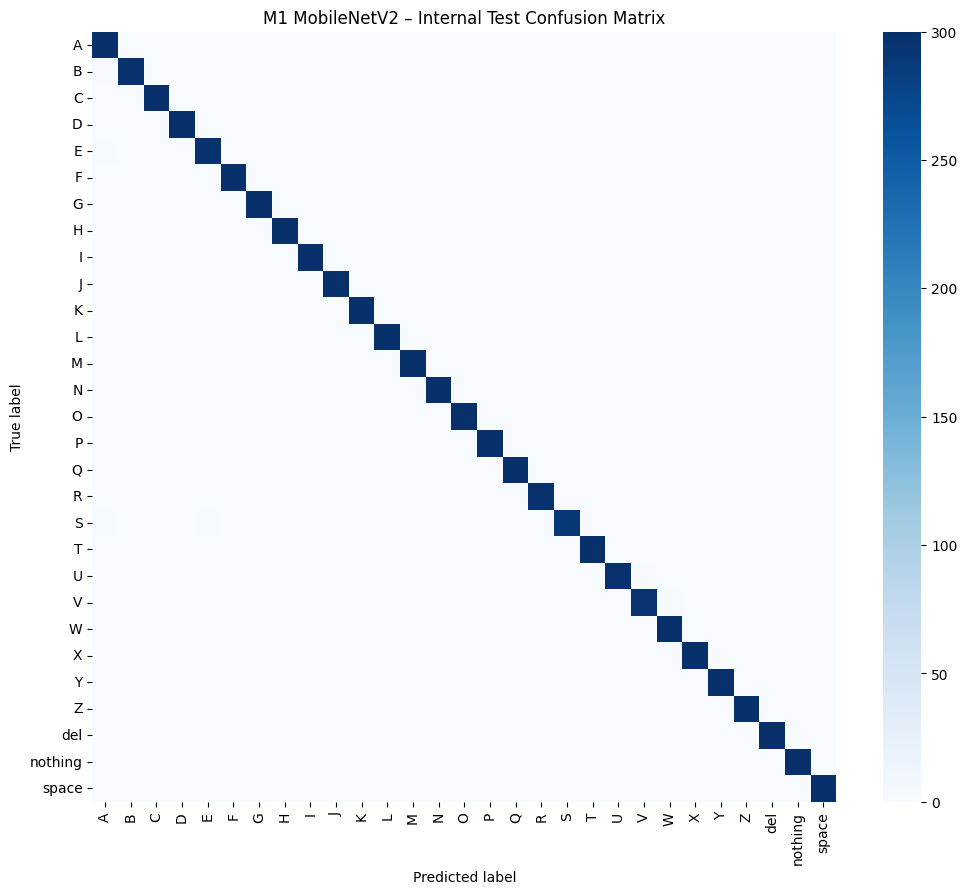

In [28]:
# M1 confusion matrix

cm_m1 = confusion_matrix(y_true_m1, y_pred_m1)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_m1,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("M1 MobileNetV2 – Internal Test Confusion Matrix")
plt.show()

## 7. External evaluation (M1, then M0)

In [29]:
# Prepare the external evaluation dataset

external_image_paths = []
external_labels = []

for class_name in class_names:
    class_path = Path(EXTERNAL_DATA_DIR) / class_name

    for image_file in class_path.iterdir():
        if image_file.is_file():
            external_image_paths.append(str(image_file))
            external_labels.append(class_name)

print("Total external images:", len(external_image_paths))
print("Number of external classes:", len(set(external_labels)))

Total external images: 870
Number of external classes: 29


In [30]:
# Create external dataset for final evaluation

external_labels_encoded = [
    class_to_index[label] for label in external_labels
]

external_ds = tf.data.Dataset.from_tensor_slices(
    (external_image_paths, external_labels_encoded)
)

external_ds = (
    external_ds
    .map(load_and_preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("External evaluation dataset created successfully!")

External evaluation dataset created successfully!


In [31]:
# M1 evaluation on the untouched external dataset

y_true_external = np.array(external_labels_encoded)

y_prob_external_m1 = m1_model.predict(external_ds)
y_pred_external_m1 = np.argmax(y_prob_external_m1, axis=1)

m1_external_accuracy = accuracy_score(
    y_true_external,
    y_pred_external_m1
)

m1_external_macro_f1 = f1_score(
    y_true_external,
    y_pred_external_m1,
    average="macro"
)

print(f"M1 External Accuracy: {m1_external_accuracy:.4f}")
print(f"M1 External Macro-F1: {m1_external_macro_f1:.4f}")

27/28 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step

2026-10-06 22:26:54.115925: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 22:26:54.252314: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 598ms/step
M1 External Accuracy: 0.2736
M1 External Macro-F1: 0.2615


In [32]:
# M1 external classification report

print(classification_report(
    y_true_external,
    y_pred_external_m1,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           A     0.3000    0.3000    0.3000        30
           B     0.3684    0.2333    0.2857        30
           C     1.0000    0.1000    0.1818        30
           D     0.4000    0.1333    0.2000        30
           E     0.6667    0.2000    0.3077        30
           F     0.4500    0.3000    0.3600        30
           G     0.2152    0.5667    0.3119        30
           H     0.3333    0.4000    0.3636        30
           I     0.2500    0.0667    0.1053        30
           J     0.0938    0.2000    0.1277        30
           K     0.3636    0.2667    0.3077        30
           L     0.3333    0.0667    0.1111        30
           M     0.3429    0.4000    0.3692        30
           N     0.1833    0.3667    0.2444        30
           O     0.3333    0.4333    0.3768        30
           P     0.6452    0.6667    0.6557        30
           Q     0.3125    0.1667    0.2174        30
           R     0.6000    

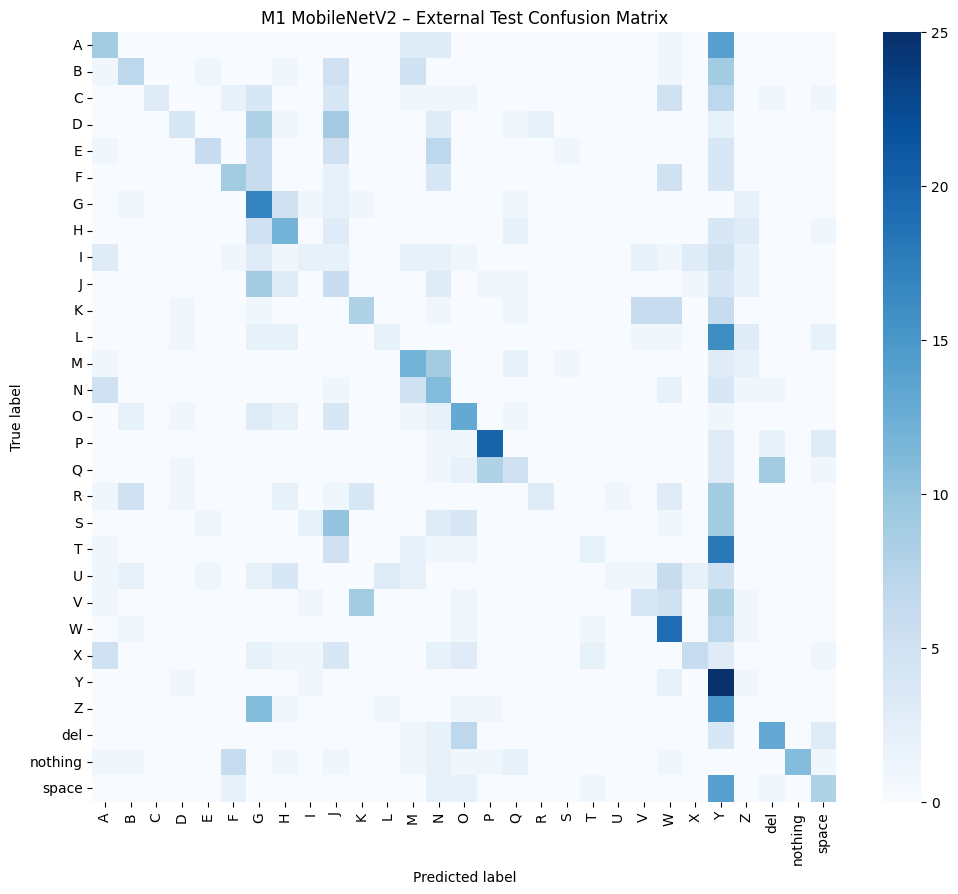

In [33]:
# M1 external confusion matrix

cm_external_m1 = confusion_matrix(
    y_true_external,
    y_pred_external_m1
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_external_m1,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("M1 MobileNetV2 – External Test Confusion Matrix")

plt.show()

In [34]:
# M0 preprocessing for the external dataset

def load_and_preprocess_m0(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

external_ds_m0 = tf.data.Dataset.from_tensor_slices(
    (external_image_paths, external_labels_encoded)
)

external_ds_m0 = (
    external_ds_m0
    .map(load_and_preprocess_m0, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("External M0 evaluation dataset created successfully!")

External M0 evaluation dataset created successfully!


In [35]:
# M0 evaluation on the untouched external dataset

y_prob_external_m0 = baseline_cnn.predict(external_ds_m0)
y_pred_external_m0 = np.argmax(y_prob_external_m0, axis=1)

m0_external_accuracy = accuracy_score(
    y_true_external,
    y_pred_external_m0
)

m0_external_macro_f1 = f1_score(
    y_true_external,
    y_pred_external_m0,
    average="macro"
)

print(f"M0 External Accuracy: {m0_external_accuracy:.4f}")
print(f"M0 External Macro-F1: {m0_external_macro_f1:.4f}")

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step
M0 External Accuracy: 0.2172
M0 External Macro-F1: 0.1850


## 8. M2 - MobileNetV2 + augmentation

In [36]:
data_augmentation_fixed = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.05),
    layers.RandomBrightness(0.10, value_range=(0, 1))
], name="data_augmentation_fixed")

print("Corrected augmentation pipeline created.")

Corrected augmentation pipeline created.


In [37]:
base_model_m2_corrected = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model_m2_corrected.trainable = False

m2_corrected = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation_fixed,
    layers.Rescaling(2.0, offset=-1),
    base_model_m2_corrected,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

m2_corrected.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

m2_corrected.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_fixed         │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │        37,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,295,133 (8.76 MB)

 Trainable params: 37,149 (145.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [38]:
early_stopping_m2_corrected = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint_m2_corrected = keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_mobilenetv2_augmented_corrected.keras",
    monitor="val_loss",
    save_best_only=True
)

history_m2_corrected = m2_corrected.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping_m2_corrected,
        checkpoint_m2_corrected
    ]
)

Epoch 1/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 62s 25ms/step - accuracy: 0.8135 - loss: 0.6225 - val_accuracy: 0.9426 - val_loss: 0.1864
Epoch 2/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9035 - loss: 0.2996 - val_accuracy: 0.9370 - val_loss: 0.1799
Epoch 3/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9132 - loss: 0.2656 - val_accuracy: 0.9390 - val_loss: 0.1901
Epoch 4/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9177 - loss: 0.2449 - val_accuracy: 0.9572 - val_loss: 0.1319
Epoch 5/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9215 - loss: 0.2350 - val_accuracy: 0.9464 - val_loss: 0.1711
Epoch 6/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9220 - loss: 0.2328 - val_accuracy: 0.9522 - val_loss: 0.1403
Epoch 7/15
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9246 - loss: 0.2296 - val_accuracy: 0.9413 - val_loss: 0.1806


In [39]:
y_true_m2_corrected = np.concatenate([y.numpy() for _, y in test_ds])

y_prob_m2_corrected = m2_corrected.predict(test_ds)
y_pred_m2_corrected = np.argmax(y_prob_m2_corrected, axis=1)

m2_corrected_accuracy = accuracy_score(
    y_true_m2_corrected,
    y_pred_m2_corrected
)

m2_corrected_macro_f1 = f1_score(
    y_true_m2_corrected,
    y_pred_m2_corrected,
    average="macro"
)

print(
    f"M2 Corrected Internal Test Accuracy: "
    f"{m2_corrected_accuracy:.4f} ({m2_corrected_accuracy*100:.2f}%)"
)

print(
    f"M2 Corrected Internal Test Macro-F1: "
    f"{m2_corrected_macro_f1:.4f} ({m2_corrected_macro_f1*100:.2f}%)"
)

272/272 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step
M2 Corrected Internal Test Accuracy: 0.9582 (95.82%)
M2 Corrected Internal Test Macro-F1: 0.9587 (95.87%)


In [40]:
# FIXED: m2_corrected has Rescaling(2.0, offset=-1) inside it, so it needs [0,1] inputs.
# Use the [0,1] external pipeline (external_ds_m0), NOT the MobileNet [-1,1] one.
imgs, _ = next(iter(external_ds_m0))
print("External [0,1] pipeline range:", float(tf.reduce_min(imgs)), float(tf.reduce_max(imgs)))

y_prob_external_m2 = m2_corrected.predict(external_ds_m0)
y_pred_external_m2 = np.argmax(y_prob_external_m2, axis=1)

m2_external_accuracy = accuracy_score(y_true_external, y_pred_external_m2)
m2_external_macro_f1 = f1_score(y_true_external, y_pred_external_m2, average="macro")

print(f"M2 Corrected External Accuracy: {m2_external_accuracy:.4f} ({m2_external_accuracy*100:.2f}%)")
print(f"M2 Corrected External Macro-F1: {m2_external_macro_f1:.4f} ({m2_external_macro_f1*100:.2f}%)")


External [0,1] pipeline range: 0.0 1.0
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
M2 Corrected External Accuracy: 0.2724 (27.24%)
M2 Corrected External Macro-F1: 0.2714 (27.14%)


M2 Corrected — External Classification Report
              precision    recall  f1-score   support

           A     0.2000    0.3000    0.2400        30
           B     0.4706    0.2667    0.3404        30
           C     1.0000    0.1333    0.2353        30
           D     0.4000    0.0667    0.1143        30
           E     0.2727    0.1000    0.1463        30
           F     0.4000    0.1333    0.2000        30
           G     0.4444    0.2667    0.3333        30
           H     0.2821    0.3667    0.3188        30
           I     0.4000    0.1333    0.2000        30
           J     0.0732    0.1000    0.0845        30
           K     0.4000    0.2000    0.2667        30
           L     0.1562    0.1667    0.1613        30
           M     0.3000    0.3000    0.3000        30
           N     0.4167    0.1667    0.2381        30
           O     0.4250    0.5667    0.4857        30
           P     0.4462    0.9667    0.6105        30
           Q     0.3333    0.1333  

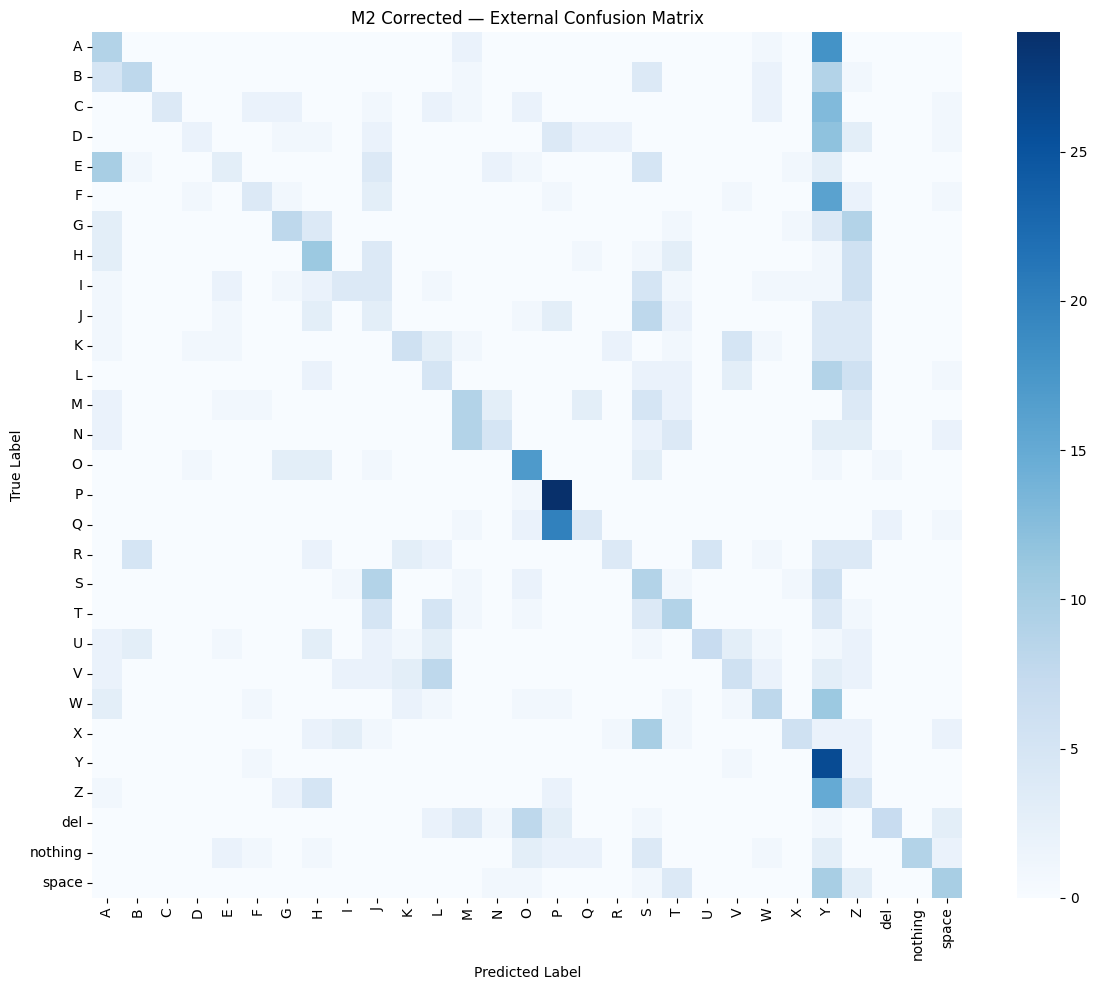

In [41]:
print("M2 Corrected — External Classification Report")
print(
    classification_report(
        y_true_external,
        y_pred_external_m2,
        target_names=class_names,
        digits=4
    )
)

cm_m2_external = confusion_matrix(
    y_true_external,
    y_pred_external_m2
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_m2_external,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("M2 Corrected — External Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Results: internal vs external

In [42]:
results = pd.DataFrame({
    "Model": [
        "M0 - CNN",
        "M1 - MobileNetV2",
        "M2 - MobileNetV2 + Augmentation"
    ],
    "Internal Accuracy": [
        m0_accuracy,
        m1_accuracy,
        m2_corrected_accuracy
    ],
    "Internal Macro-F1": [
        m0_macro_f1,
        m1_macro_f1,
        m2_corrected_macro_f1
    ],
    "External Accuracy": [
        m0_external_accuracy,
        m1_external_accuracy,
        m2_external_accuracy
    ],
    "External Macro-F1": [
        m0_external_macro_f1,
        m1_external_macro_f1,
        m2_external_macro_f1
    ]
})

results

,Model,Internal Accuracy,Internal Macro-F1,External Accuracy,External Macro-F1
0,M0 - CNN,0.998391,0.998391,0.217241,0.185005
1,M1 - MobileNetV2,0.996782,0.996780,0.273563,0.261517
2,M2 - MobileNetV2 + Augmentation,0.958161,0.958732,0.272414,0.271378


In [43]:
print("M1 — External Classification Report")
print(
    classification_report(
        y_true_external,
        y_pred_external_m1,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

M1 — External Classification Report
              precision    recall  f1-score   support

           A     0.3000    0.3000    0.3000        30
           B     0.3684    0.2333    0.2857        30
           C     1.0000    0.1000    0.1818        30
           D     0.4000    0.1333    0.2000        30
           E     0.6667    0.2000    0.3077        30
           F     0.4500    0.3000    0.3600        30
           G     0.2152    0.5667    0.3119        30
           H     0.3333    0.4000    0.3636        30
           I     0.2500    0.0667    0.1053        30
           J     0.0938    0.2000    0.1277        30
           K     0.3636    0.2667    0.3077        30
           L     0.3333    0.0667    0.1111        30
           M     0.3429    0.4000    0.3692        30
           N     0.1833    0.3667    0.2444        30
           O     0.3333    0.4333    0.3768        30
           P     0.6452    0.6667    0.6557        30
           Q     0.3125    0.1667    0.2174  

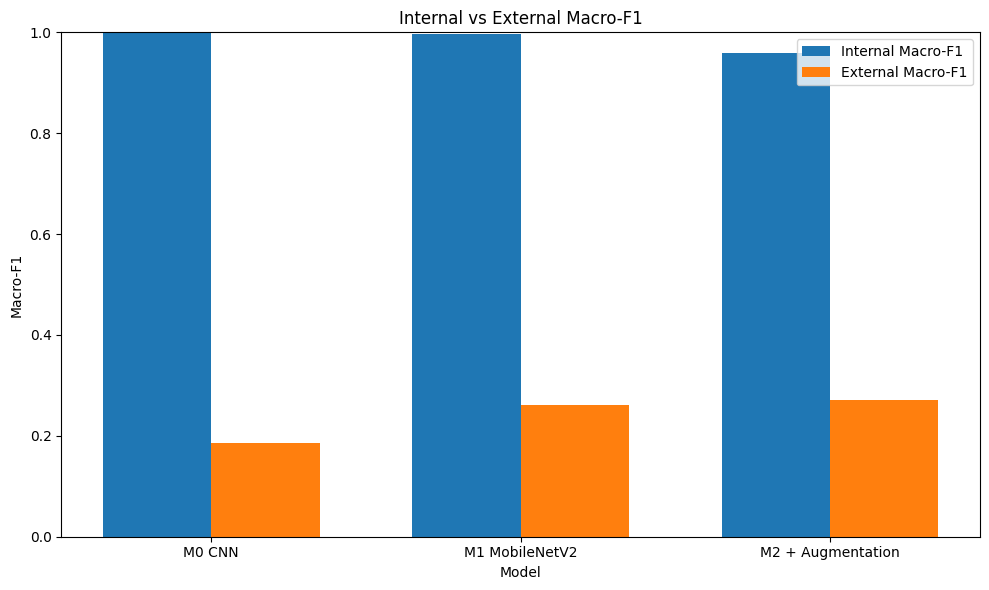

In [44]:
models = results["Model"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    results["Internal Macro-F1"],
    width,
    label="Internal Macro-F1"
)

plt.bar(
    x + width / 2,
    results["External Macro-F1"],
    width,
    label="External Macro-F1"
)

plt.xticks(x, ["M0 CNN", "M1 MobileNetV2", "M2 + Augmentation"])
plt.ylabel("Macro-F1")
plt.xlabel("Model")
plt.title("Internal vs External Macro-F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

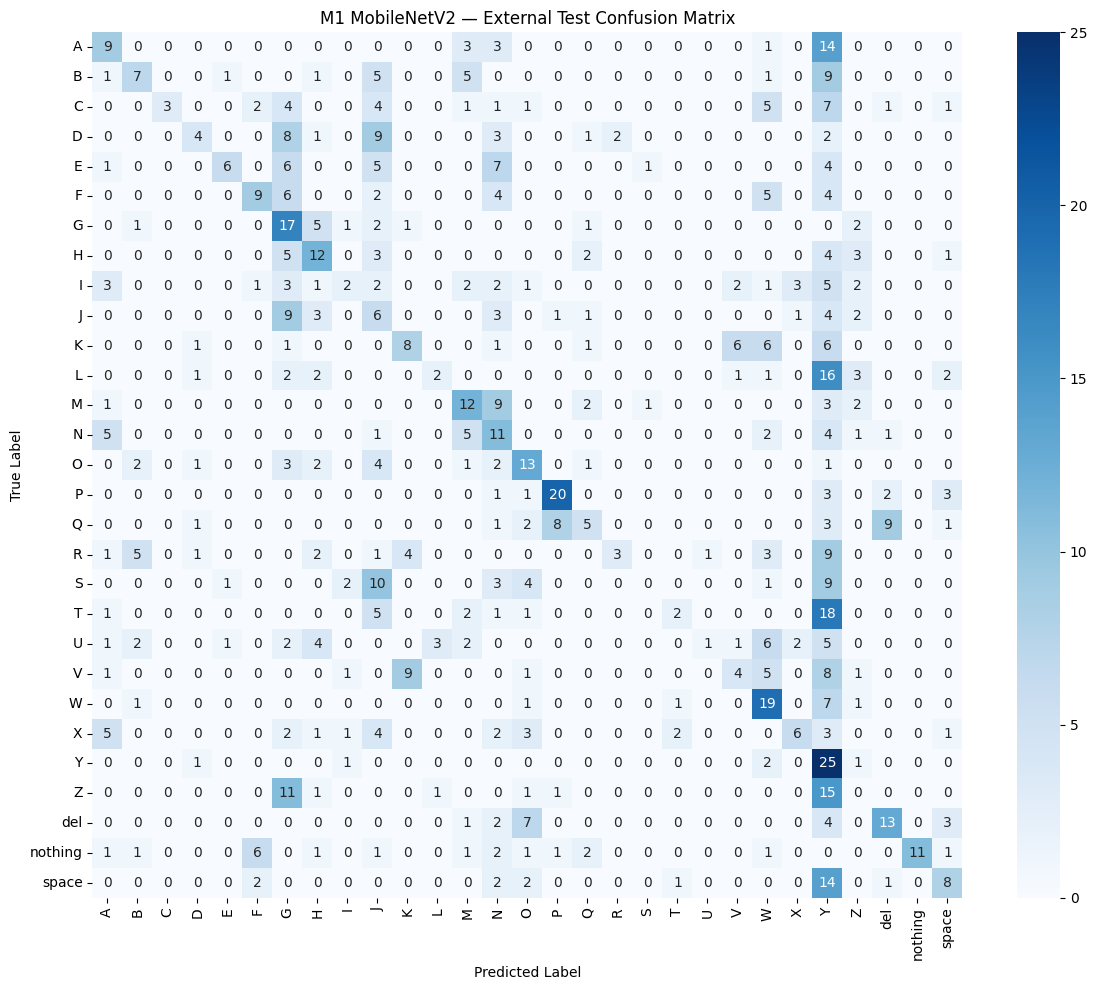

In [45]:
cm_m1_external = confusion_matrix(
    y_true_external,
    y_pred_external_m1
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_m1_external,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("M1 MobileNetV2 — External Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
baseline_cnn.save("/kaggle/working/final_M0_CNN.keras")
m1_model.save("/kaggle/working/final_M1_MobileNetV2.keras")
m2_corrected.save("/kaggle/working/final_M2_MobileNetV2_Augmentation.keras")

print("All three final models saved successfully.")

All three final models saved successfully.


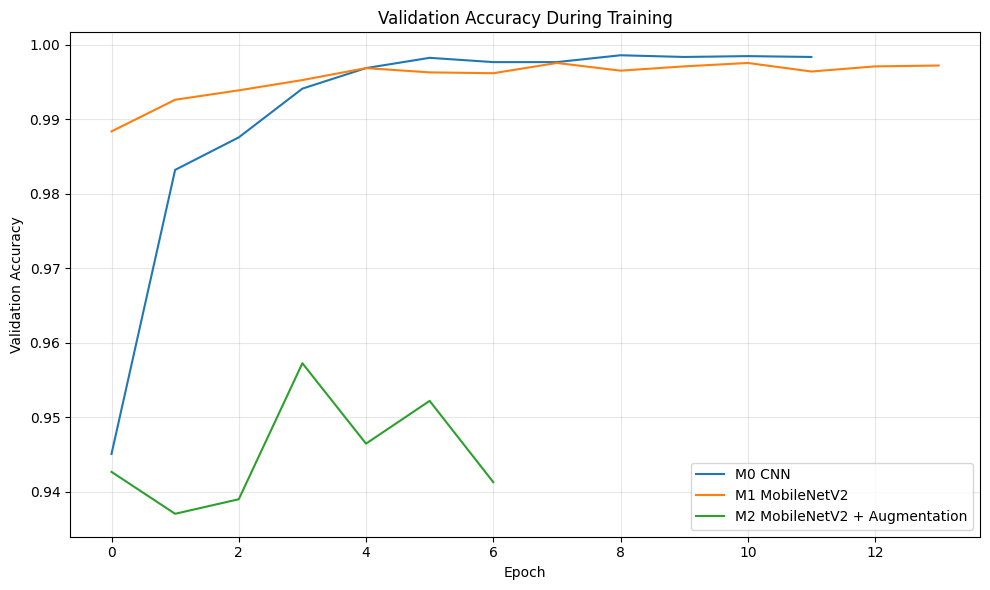

In [47]:
fig = plt.figure(figsize=(10, 6))

plt.plot(
    history_m0.history["val_accuracy"],
    label="M0 CNN"
)

plt.plot(
    history_m1.history["val_accuracy"],
    label="M1 MobileNetV2"
)

plt.plot(
    history_m2_corrected.history["val_accuracy"],
    label="M2 MobileNetV2 + Augmentation"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy During Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

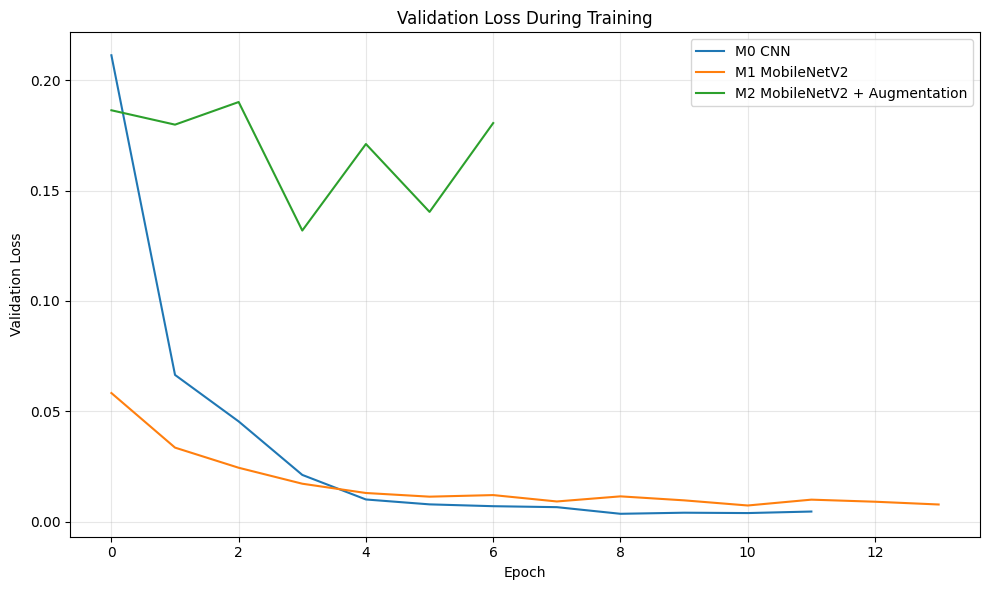

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_m0.history["val_loss"],
    label="M0 CNN"
)

plt.plot(
    history_m1.history["val_loss"],
    label="M1 MobileNetV2"
)

plt.plot(
    history_m2_corrected.history["val_loss"],
    label="M2 MobileNetV2 + Augmentation"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss During Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
final_summary = pd.DataFrame({
    "Model": [
        "M0 - CNN",
        "M1 - MobileNetV2",
        "M2 - MobileNetV2 + Augmentation"
    ],
    "Internal Accuracy": [
        m0_accuracy,
        m1_accuracy,
        m2_corrected_accuracy
    ],
    "Internal Macro-F1": [
        m0_macro_f1,
        m1_macro_f1,
        m2_corrected_macro_f1
    ],
    "External Accuracy": [
        m0_external_accuracy,
        m1_external_accuracy,
        m2_external_accuracy
    ],
    "External Macro-F1": [
        m0_external_macro_f1,
        m1_external_macro_f1,
        m2_external_macro_f1
    ]
})

final_summary_rounded = final_summary.copy()

metric_columns = [
    "Internal Accuracy",
    "Internal Macro-F1",
    "External Accuracy",
    "External Macro-F1"
]

final_summary_rounded[metric_columns] = (
    final_summary_rounded[metric_columns] * 100
).round(2)

final_summary_rounded

,Model,Internal Accuracy,Internal Macro-F1,External Accuracy,External Macro-F1
0,M0 - CNN,99.84,99.84,21.72,18.50
1,M1 - MobileNetV2,99.68,99.68,27.36,26.15
2,M2 - MobileNetV2 + Augmentation,95.82,95.87,27.24,27.14


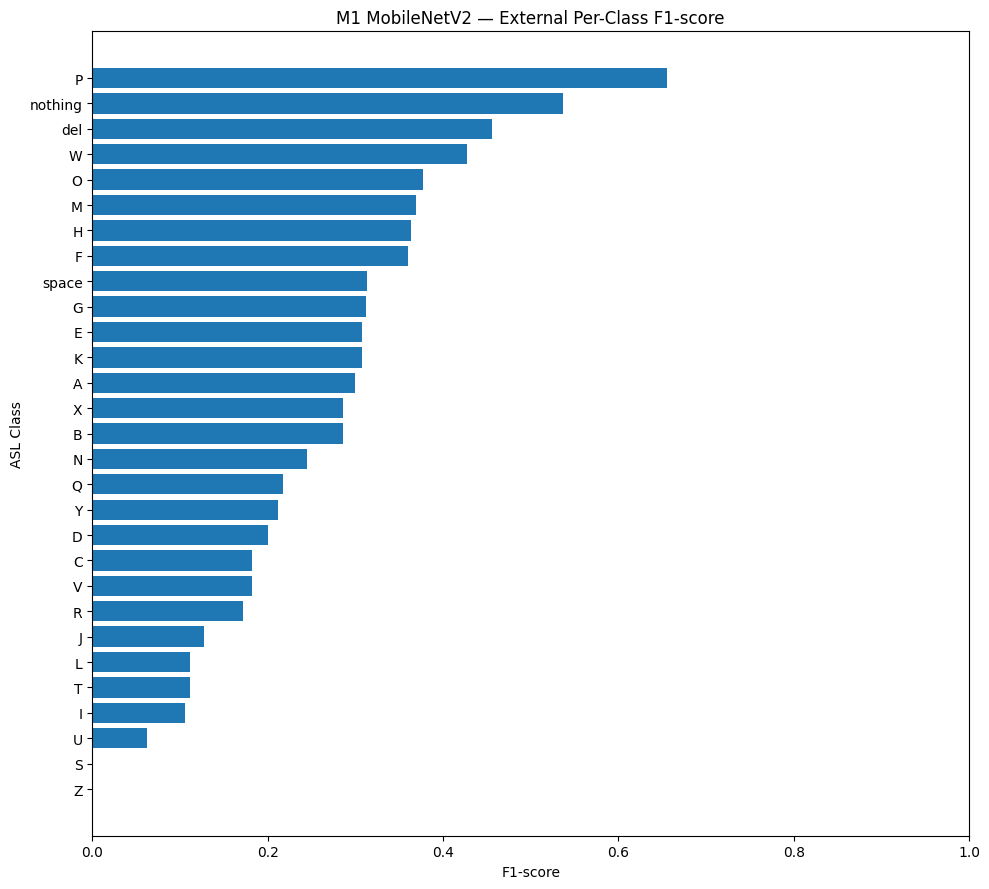

In [50]:
m1_report = classification_report(
    y_true_external,
    y_pred_external_m1,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_f1 = pd.DataFrame({
    "Class": class_names,
    "F1": [m1_report[class_name]["f1-score"] for class_name in class_names]
})

per_class_f1 = per_class_f1.sort_values("F1", ascending=True)

plt.figure(figsize=(10, 9))

plt.barh(
    per_class_f1["Class"],
    per_class_f1["F1"]
)

plt.xlabel("F1-score")
plt.ylabel("ASL Class")
plt.title("M1 MobileNetV2 — External Per-Class F1-score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [51]:
final_results = {
    "M0_CNN": {
        "internal_accuracy": float(m0_accuracy),
        "internal_macro_f1": float(m0_macro_f1),
        "external_accuracy": float(m0_external_accuracy),
        "external_macro_f1": float(m0_external_macro_f1),
    },
    "M1_MobileNetV2": {
        "internal_accuracy": float(m1_accuracy),
        "internal_macro_f1": float(m1_macro_f1),
        "external_accuracy": float(m1_external_accuracy),
        "external_macro_f1": float(m1_external_macro_f1),
    },
    "M2_MobileNetV2_Augmentation": {
        "internal_accuracy": float(m2_corrected_accuracy),
        "internal_macro_f1": float(m2_corrected_macro_f1),
        "external_accuracy": float(m2_external_accuracy),
        "external_macro_f1": float(m2_external_macro_f1),
    }
}

final_results

{'M0_CNN': {'internal_accuracy': 0.9983908045977011,
  'internal_macro_f1': 0.998390779664041,
  'external_accuracy': 0.21724137931034482,
  'external_macro_f1': 0.18500532105008194},
 'M1_MobileNetV2': {'internal_accuracy': 0.9967816091954023,
  'internal_macro_f1': 0.9967804411822987,
  'external_accuracy': 0.2735632183908046,
  'external_macro_f1': 0.2615166816755003},
 'M2_MobileNetV2_Augmentation': {'internal_accuracy': 0.9581609195402299,
  'internal_macro_f1': 0.9587322371843181,
  'external_accuracy': 0.27241379310344827,
  'external_macro_f1': 0.2713780755973644}}

In [52]:
print("=== FINAL EXPERIMENT CONFIGURATION ===")
print(f"TensorFlow version: {tf.__version__}")
print(f"Image size: {IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Internal test samples: {len(X_test)}")
print(f"External test samples: {len(external_image_paths)}")
print("Random seed: 42")
print("Optimizer: Adam")
print("Initial learning rate: 0.001")
print("Early stopping monitor: val_loss")
print("Early stopping patience: 3")
print("Restore best weights: True")

=== FINAL EXPERIMENT CONFIGURATION ===
TensorFlow version: 2.20.0
Image size: (128, 128)
Batch size: 32
Number of classes: 29
Training samples: 69600
Validation samples: 8700
Internal test samples: 8700
External test samples: 870
Random seed: 42
Optimizer: Adam
Initial learning rate: 0.001
Early stopping monitor: val_loss
Early stopping patience: 3
Restore best weights: True


## 10. Exact duplicate audit (SHA-256)

In [53]:
import hashlib
from collections import defaultdict

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

split_paths = {
    "train": X_train,
    "validation": X_val,
    "internal_test": X_test
}

hash_to_splits = defaultdict(set)

for split_name, paths in split_paths.items():
    for path in paths:
        hash_to_splits[file_hash(path)].add(split_name)

cross_split_duplicates = {
    h: splits
    for h, splits in hash_to_splits.items()
    if len(splits) > 1
}

print("=== EXACT DUPLICATE AUDIT ===")
print(f"Unique image hashes: {len(hash_to_splits):,}")
print(f"Cross-split duplicate hashes: {len(cross_split_duplicates):,}")

if cross_split_duplicates:
    print("\nWARNING: Exact duplicate files occur across multiple splits.")
    for h, splits in list(cross_split_duplicates.items())[:10]:
        print(h, "->", sorted(splits))
else:
    print("No exact duplicate files were found across train, validation, and internal test.")

=== EXACT DUPLICATE AUDIT ===
Unique image hashes: 87,000
Cross-split duplicate hashes: 0
No exact duplicate files were found across train, validation, and internal test.


## 11. Error analysis

### 11.1 Per-class external F1 for all models

,M0,M1,M2
Z,0.491,0.000,0.101
S,0.000,0.000,0.189
U,0.059,0.062,0.333
I,0.078,0.105,0.200
T,0.059,0.111,0.290
L,0.265,0.111,0.161
J,0.265,0.128,0.085
R,0.246,0.171,0.205
V,0.000,0.182,0.240
C,0.151,0.182,0.235


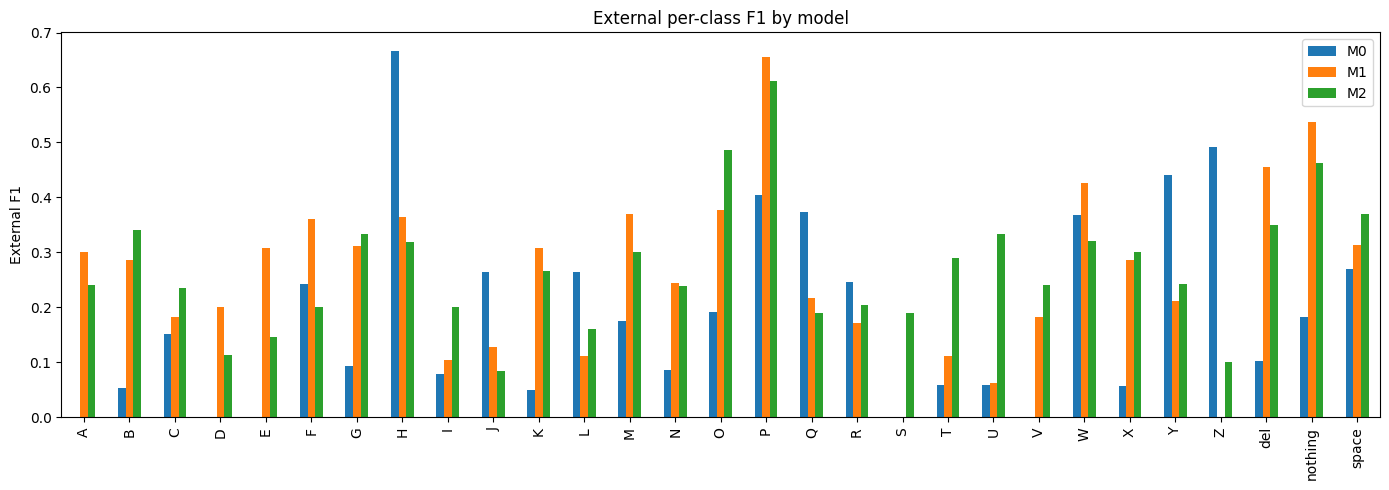

In [54]:
labels_all = list(range(NUM_CLASSES))
per_class = pd.DataFrame({
    "M0": f1_score(y_true_external, y_pred_external_m0, average=None, labels=labels_all, zero_division=0),
    "M1": f1_score(y_true_external, y_pred_external_m1, average=None, labels=labels_all, zero_division=0),
    "M2": f1_score(y_true_external, y_pred_external_m2, average=None, labels=labels_all, zero_division=0),
}, index=class_names).round(3)
display(per_class.sort_values("M1"))

per_class.plot(kind="bar", figsize=(14, 5))
plt.ylabel("External F1"); plt.title("External per-class F1 by model")
plt.tight_layout(); plt.show()


### 11.2 Most confused classes (M1, external)

In [55]:
cm = confusion_matrix(y_true_external, y_pred_external_m1, labels=labels_all).copy()
np.fill_diagonal(cm, 0)
pairs = sorted(
    [(int(cm[i, j]), class_names[i], class_names[j])
     for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0],
    reverse=True)
print("Top 10 external confusions for M1 (count, TRUE -> PREDICTED):")
for c, t, p in pairs[:10]:
    print(f"  {c:2d}  {t} -> {p}")

print("\nWhat the weakest classes get predicted as:")
for cls in ["Z", "U", "L", "J", "I", "S"]:
    i = class_names.index(cls)
    top = np.argsort(-cm[i])[:3]
    print(f"  {cls}: " + ", ".join(f"{class_names[j]} ({cm[i, j]})" for j in top if cm[i, j] > 0))


Top 10 external confusions for M1 (count, TRUE -> PREDICTED):
  18  T -> Y
  16  L -> Y
  15  Z -> Y
  14  space -> Y
  14  A -> Y
  11  Z -> G
  10  S -> J
   9  V -> K
   9  S -> Y
   9  R -> Y

What the weakest classes get predicted as:
  Z: Y (15), G (11), P (1)
  U: W (6), Y (5), H (4)
  L: Y (16), Z (3), G (2)
  J: G (9), Y (4), N (3)
  I: Y (5), A (3), X (3)
  S: J (10), Y (9), O (4)


### 11.3 Misclassified external images vs a training example
Write 2-3 sentences in the report about what you see (background, hand size/crop, lighting). J and Z are motion signs, so a static photo cannot capture them.

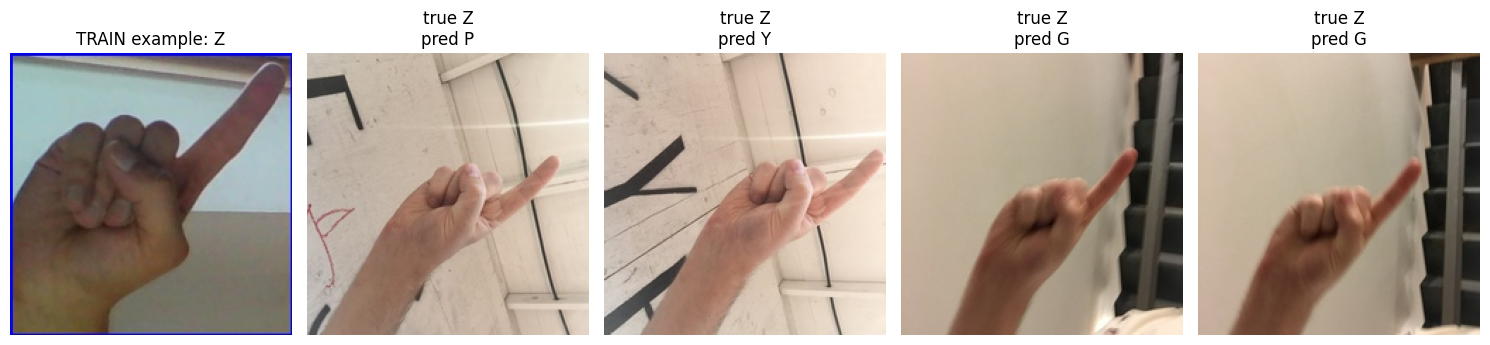

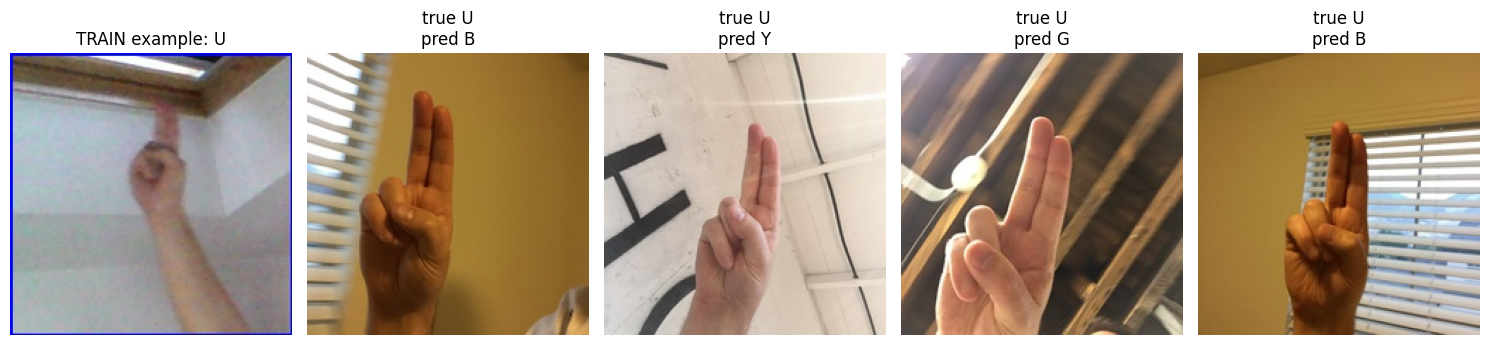

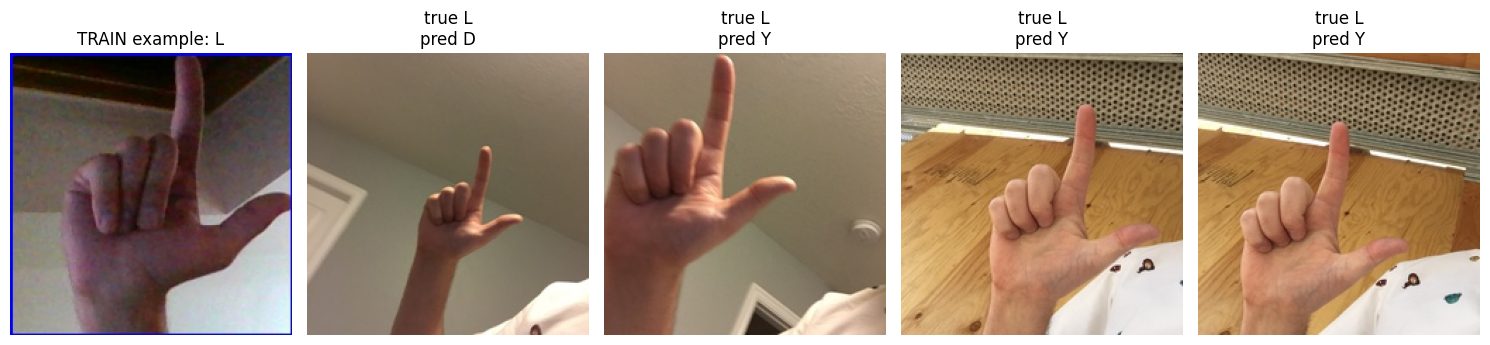

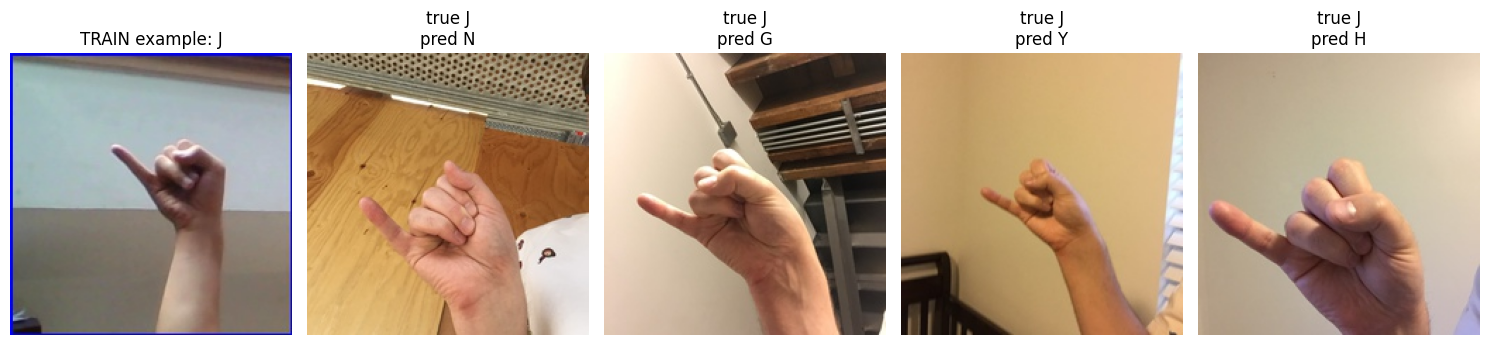

In [56]:
from PIL import Image
import random
random.seed(42)

def show_errors(true_cls, n=4):
    ti = class_names.index(true_cls)
    wrong = [k for k in range(len(y_true_external))
             if y_true_external[k] == ti and y_pred_external_m1[k] != ti]
    wrong = random.sample(wrong, min(n, len(wrong)))
    train_example = next(p for p, l in zip(X_train, y_train) if l == true_cls)
    fig, axes = plt.subplots(1, len(wrong) + 1, figsize=(3 * (len(wrong) + 1), 3.4))
    axes[0].imshow(Image.open(train_example)); axes[0].set_title(f"TRAIN example: {true_cls}")
    for ax, k in zip(axes[1:], wrong):
        ax.imshow(Image.open(external_image_paths[k]))
        ax.set_title(f"true {true_cls}\npred {class_names[y_pred_external_m1[k]]}")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

for c in ["Z", "U", "L", "J"]:
    show_errors(c)

# Also write 2-3 sentences in the report: backgrounds, hand size/crop,
# lighting, and that J and Z are MOTION signs (a static photo cannot
# capture the movement), which your proposal flagged.


## 12. Near-duplicate / leakage check (perceptual hash)
Slow cell (a few minutes). Report the three percentages it prints.

In [57]:
from concurrent.futures import ThreadPoolExecutor

def dhash(path, size=8):
    img = Image.open(path).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(img, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return np.packbits(bits).view(">u8")[0].astype(np.uint64)

def hash_all(paths):
    with ThreadPoolExecutor(8) as ex:
        return np.array(list(ex.map(dhash, paths)), dtype=np.uint64)

h_train = hash_all(X_train)
h_test = hash_all(X_test)

def popcount(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    x = np.ascontiguousarray(x)
    return np.unpackbits(x.view(np.uint8).reshape(*x.shape, 8), axis=-1).sum(-1)

min_dist = np.empty(len(h_test), dtype=np.int32)
for s in range(0, len(h_test), 200):
    chunk = h_test[s:s + 200][:, None]
    min_dist[s:s + 200] = popcount(chunk ^ h_train[None, :]).min(axis=1)

for thr in (0, 2, 5):
    print(f"Internal-test images with a TRAIN image within Hamming distance <= {thr}: "
          f"{(min_dist <= thr).mean() * 100:.1f}%")
# Report these percentages. A high % means the 99.6% internal score is
# inflated by near-duplicate frames -> motivates the block split below.


Internal-test images with a TRAIN image within Hamming distance <= 0: 43.3%
Internal-test images with a TRAIN image within Hamming distance <= 2: 88.4%
Internal-test images with a TRAIN image within Hamming distance <= 5: 99.4%
